# Reproducing the paper with the `sqd_linsolve` package

Companion notebook to **T. Selim, "Extending Sample-based Quantum Diagonalization to Systems of Linear Equations."**

This notebook (i) tests the package `sqd_linsolve` and (ii) reproduces every simulator result of the paper with it. Each
reproduced number is compared with the value printed in the paper; the last cell lists all checks.

| Section | Paper |
|---|---|
| 1. Unit tests | Eqs. (pauli), (gershgorin), (config-set), Proposition 1, Remarks 1 and 2 |
| 2. The $4\times4$ example | Sec. IV A, Fig. 2, Tables I–III, Fig. 3 (simulators; hardware from stored counts) |
| 3. Localized problem, $N=1024$ | Sec. IV B, Tables IV and V, Fig. 4(a) |
| 4. Noise, shots, Trotter errors | Sec. IV C, Fig. 4(c)–(d) |
| 5. Circuit cost and dense matrices | Sec. IV D, Fig. 4(b), Table VI |
| 6. Scaling with $N$ | Sec. IV E, Fig. 5 |
| 7. Classical comparison | Sec. IV F |
| 8. Summary of checks | all |

**Run time:** about 10 minutes, most of it for the dense ensemble of Table VI (`RUN_DENSE_ENSEMBLE`).
No IBM Quantum account is needed. The hardware results of Fig. 3 and Table III are included if the file
`data/ibm_fez_4x4_counts.json` is present (it is written by the export cell of the self-contained notebook).

**Requirements:** `pip install -r requirements.txt` (Qiskit $\ge$ 2.3, Qiskit Aer $\ge$ 0.17, NumPy, SciPy, pandas, Matplotlib).
Run the notebook from the package root (the folder that contains `sqd_linsolve/`).

In [1]:
import os, sys, json, time, warnings
import numpy as np
import pandas as pd
import scipy.linalg as sl
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
# make the package importable from the package root, from anc/, or from the folder that contains anc/
for root in (".", "sqd_linsolve", "anc/sqd_linsolve", ".."):
    if os.path.isfile(os.path.join(root, "sqd_linsolve", "__init__.py")):
        sys.path.insert(0, os.path.abspath(root))
        break
import qiskit, qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
import sqd_linsolve as sq
from sqd_linsolve import BackendRunner

print(f"sqd_linsolve {sq.__version__} | Qiskit {qiskit.__version__} | Qiskit Aer {qiskit_aer.__version__} | "
      f"NumPy {np.__version__} | SciPy {__import__('scipy').__version__} | Python {sys.version.split()[0]}")

RUN_DENSE_ENSEMBLE = True     # Table VI: 30 random instances per N (about 5 minutes)
RUN_CIRCUITS = True           # circuit runs of Table IV and Fig. 5 (about 1 minute)
FIG_DIR = "figures"
HW_FILE = next((p for p in ("data/ibm_fez_4x4_counts.json", "../data/ibm_fez_4x4_counts.json",
                            "anc/data/ibm_fez_4x4_counts.json", "../../data/ibm_fez_4x4_counts.json") if os.path.exists(p)),
               "data/ibm_fez_4x4_counts.json")   # written by cell B15 of the self-contained notebook
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
np.set_printoptions(precision=4, suppress=True, linewidth=120)
T_START = time.time()

sqd_linsolve 1.1.0 | Qiskit 2.5.2 | Qiskit Aer 0.17.2 | NumPy 2.5.3 | SciPy 1.18.1 | Python 3.13.16


In [2]:
# ---- bookkeeping of the comparisons with the paper ----
CHECKS, SECTION = [], ""

def _fmt(v):
    if isinstance(v, (float, np.floating)):
        return f"{v:.4g}"
    return str(v)

def check(item, value, paper, atol=None, rtol=None, cond=None):
    # Compare a reproduced value with the paper. Exact comparison unless atol/rtol is given;
    # `cond` (bool) overrides the comparison for inequalities such as 'below 3e-14'.
    if cond is not None:
        ok = bool(cond)
    elif atol is None and rtol is None:
        ok = bool(np.all(np.asarray(value) == np.asarray(paper)))
    else:
        ok = bool(np.allclose(value, paper, atol=atol or 0.0, rtol=rtol or 0.0))
    CHECKS.append(dict(section=SECTION, item=item, reproduced=_fmt(value), paper=_fmt(paper), ok=ok))
    print(f"[{'PASS' if ok else 'FAIL'}] {item}: {_fmt(value)}   (paper: {_fmt(paper)})")

# ---- shared helpers (same procedure as Part C of the self-contained notebook) ----
nm = NoiseModel()                                                    # noise model of Fig. 3 and Fig. 5
nm.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ["cx"])
nm.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ["sx", "x"])
nm.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.02, 0.98]]))

def make_problem(family, N):
    return sq.screened_poisson_system(N, 0.5) if family == "banded" else sq.random_spd_point(N)

_CASES = {}
def run_case(family, N, mode, seed=0, M=8, shots=2000, tol=1e-2, s_max=64):
    # One point of the scaling test: Gershgorin time step, M times, untruncated and truncated (R = max(2, N/8)) solutions.
    key = (family, N, mode, seed)
    if key in _CASES:
        return _CASES[key]
    A, b = make_problem(family, N)
    x_ref = np.linalg.solve(A.toarray() if sp.issparse(A) else A, b)
    times = np.pi / sq.spectral_width_bound(A) * np.arange(1, M + 1)
    row = dict(family=family, mode=mode, N=N, L=np.nan, S=np.nan, trotter_inf=0.0, cx_per_circuit=np.nan)
    t0 = time.time()
    if mode == "exact-emulation":
        counts = sq.sample_exact(A, b, times, shots, seed)
    else:
        op = sq.pauli_op(A)
        S, inf = sq.choose_trotter_steps(op, A, b, times[-1], tol=tol, s_max=s_max)
        cx, _ = sq.circuit_cost(op, b, times[-1], S)
        runner = (BackendRunner("simulator", seed=seed) if mode == "simulator"
                  else BackendRunner("noisy_simulator", noise_model=nm, seed=seed))
        counts = sq.sample_configurations(op, b, times, shots, S, runner)
        row.update(L=len(op), S=S, trotter_inf=inf, cx_per_circuit=cx)
    C = sq.configuration_set(counts, b)
    m = sq.metrics(A, x_ref, sq.galerkin(A, b, C))
    R_tr = max(2, N // 8)
    row.update(R=len(C), R_over_N=len(C) / N, F=m["F"], rel_err=m["rel_err"], A_norm_err=m["Anorm"], R_trunc=R_tr,
               F_trunc_SQD=sq.metrics(A, x_ref, sq.galerkin(A, b, sq.configuration_set(counts, b, max_R=R_tr)))["F"],
               F_trunc_oracle=sq.metrics(A, x_ref, sq.galerkin(A, b, sq.oracle_set(x_ref, R_tr)))["F"],
               seconds=round(time.time() - t0, 1), C=C)
    _CASES[key] = row
    return row

---
## 1. Unit tests of the package
Properties stated in Sec. II of the paper, tested on small random instances.

In [3]:
SECTION = "1 unit tests"
rng = np.random.default_rng(2026)

# Eq. (pauli): exact reconstruction and the number of terms for the three matrix classes
N = 8; n = 3
H = rng.normal(size=(N, N)) + 1j * rng.normal(size=(N, N)); H = H + H.conj().T
Sy = rng.normal(size=(N, N)); Sy = Sy + Sy.T
D = np.diag(rng.normal(size=N))
for name, Amat, L_exp in [("complex Hermitian", H, N**2), ("real symmetric", Sy, N*(N+1)//2), ("diagonal", D, N)]:
    op = sq.pauli_op(Amat)
    check(f"Pauli terms of a generic {name} matrix (N=8)", len(op), L_exp)
    check(f"Pauli reconstruction error, {name}", float(np.abs(op.to_matrix() - Amat).max()), 0.0, cond=np.abs(op.to_matrix() - Amat).max() < 1e-12)
odd_y = sum(str(p).count("Y") % 2 for p in sq.pauli_op(Sy).paulis)
check("real symmetric: strings with an odd number of Y", odd_y, 0)

# Eq. (gershgorin) and the Pauli-sum bound are upper bounds on the spectral width
for name, Amat in [("Hermitian", H), ("symmetric", Sy)]:
    w = np.linalg.eigvalsh(Amat); width = w[-1] - w[0]
    g, p = sq.spectral_width_bound(Amat), sq.spectral_width_bound(Amat, method="pauli")
    check(f"Gershgorin bound >= true width ({name})", g, width, cond=g >= width - 1e-12)
    check(f"Pauli-sum bound >= true width ({name})", p, width, cond=p >= width - 1e-12)

# Step 3: a basis-state source is prepared with X gates only; a dense b uses initialize
op = sq.pauli_op(Sy)
names = lambda qc: {ins.operation.name for ins in qc.data}
qc_basis = sq.build_evolution_circuit(op, np.eye(N)[5], 0.3, 1)
qc_dense = sq.build_evolution_circuit(op, rng.random(N), 0.3, 1)
check("basis-state source prepared with X gates (no initialize)", "initialize" in names(qc_basis), False)
check("dense source prepared with initialize", "initialize" in names(qc_dense), True)

# Eq. (config-set): supp(b) is always included, also after truncation
b5 = np.eye(N)[5]; cnts = np.array([0, 9, 7, 0, 3, 0, 1, 0])
check("configuration set contains supp(b) although never sampled", sorted(sq.configuration_set(cnts, b5).tolist()), [1, 2, 4, 5, 6])
check("truncation keeps supp(b) plus the most frequent", sorted(sq.configuration_set(cnts, b5, max_R=2).tolist()), [1, 5])

# Galerkin step: indefinite A on the full space (pseudo-inverse branch) returns A^{-1} b
Ai = np.diag([3.0, -2.0, 1.0, -0.5]) + 0.1 * np.ones((4, 4)); bi = rng.random(4)
check("indefinite A, C = all configurations: x = A^{-1} b", float(np.abs(sq.galerkin(Ai, bi, range(4)) - np.linalg.solve(Ai, bi)).max()),
      0.0, cond=np.allclose(sq.galerkin(Ai, bi, range(4)), np.linalg.solve(Ai, bi)))

[PASS] Pauli terms of a generic complex Hermitian matrix (N=8): 64   (paper: 64)
[PASS] Pauli reconstruction error, complex Hermitian: 4.578e-16   (paper: 0)
[PASS] Pauli terms of a generic real symmetric matrix (N=8): 36   (paper: 36)
[PASS] Pauli reconstruction error, real symmetric: 5.551e-16   (paper: 0)
[PASS] Pauli terms of a generic diagonal matrix (N=8): 8   (paper: 8)
[PASS] Pauli reconstruction error, diagonal: 2.22e-16   (paper: 0)
[PASS] real symmetric: strings with an odd number of Y: 0   (paper: 0)
[PASS] Gershgorin bound >= true width (Hermitian): 33.02   (paper: 17.5)
[PASS] Pauli-sum bound >= true width (Hermitian): 74.32   (paper: 17.5)
[PASS] Gershgorin bound >= true width (symmetric): 34.84   (paper: 16.97)
[PASS] Pauli-sum bound >= true width (symmetric): 55.24   (paper: 16.97)
[PASS] basis-state source prepared with X gates (no initialize): False   (paper: False)
[PASS] dense source prepared with initialize: True   (paper: True)
[PASS] configuration set contains s

In [4]:
# Proposition 1 on a reducible matrix: two interleaved 8x8 SPD blocks, b in one block
A_h, b_h, perm = sq.hidden_block_spd(n=4, seed=7)
x_h = np.linalg.solve(A_h, b_h)
S_kr = sq.krylov_support(A_h, b_h, 15)
check("Prop. 1: Krylov support of b (hidden block, N=16)", len(S_kr), 8)
check("Prop. 1(i): supp(x) is inside the Krylov support", set(np.flatnonzero(np.abs(x_h) > 1e-12)) <= set(S_kr), True)
for t in (0.37, 1.9):
    supp_t = set(np.flatnonzero(np.abs(sl.expm(-1j * A_h * t) @ b_h) > 1e-12))
    check(f"Prop. 1(ii): supp(exp(-iAt) b) = Krylov support, t={t}", supp_t == set(S_kr), True)
check("Prop. 1(iii): Galerkin on the Krylov support is exact (rel. error)", sq.metrics(A_h, x_h, sq.galerkin(A_h, b_h, S_kr))["rel_err"],
      0.0, cond=sq.metrics(A_h, x_h, sq.galerkin(A_h, b_h, S_kr))["rel_err"] < 1e-12)

# Remark 1: enlarging C never increases the energy-norm error (2000 random nested pairs, N=32)
rng = np.random.default_rng(7)
Nr = 32; Q = rng.random((Nr, Nr)); A_r = Q @ Q.T + Nr * np.eye(Nr); b_r = rng.random(Nr); x_r = np.linalg.solve(A_r, b_r)
viol = 0
for _ in range(2000):
    k = rng.integers(2, Nr - 1); C = rng.choice(Nr, k, replace=False)
    extra = rng.choice(np.setdiff1d(np.arange(Nr), C), rng.integers(1, Nr - k + 1), replace=False)
    viol += sq.metrics(A_r, x_r, sq.galerkin(A_r, b_r, np.r_[C, extra]))["Anorm"] > sq.metrics(A_r, x_r, sq.galerkin(A_r, b_r, C))["Anorm"] + 1e-12
check("Remark 1: violations of Galerkin monotonicity in 2000 nested pairs", int(viol), 0)

# Remark 2: the long-time average of p(z|t) is sum_k |beta_k|^2 |<z|phi_k>|^2, which differs from the solution weights
Ns = 8; Q = rng.random((Ns, Ns)); A_s = Q @ Q.T + Ns * np.eye(Ns); b_s = rng.random(Ns); b_s /= np.linalg.norm(b_s)
lam, V = np.linalg.eigh(A_s); beta = V.T @ b_s; pbar = (V**2) @ (beta**2)
ts = rng.uniform(0, 5000, 20000); pavg = np.mean(np.abs((V * beta) @ np.exp(-1j * np.outer(lam, ts)))**2, axis=1)
xs = V @ (beta / lam); xs = xs**2 / np.sum(xs**2)
check("Remark 2: |time average - p_bar| (20000 random times)", float(np.abs(pavg - pbar).max()), 0.0, cond=np.abs(pavg - pbar).max() < 2e-3)
print(f"Bhattacharyya overlap of p_bar with the solution weights |x_z|^2: {np.sum(np.sqrt(pbar * xs))**2:.3f} (1 = identical)")

[PASS] Prop. 1: Krylov support of b (hidden block, N=16): 8   (paper: 8)
[PASS] Prop. 1(i): supp(x) is inside the Krylov support: True   (paper: True)
[PASS] Prop. 1(ii): supp(exp(-iAt) b) = Krylov support, t=0.37: True   (paper: True)
[PASS] Prop. 1(ii): supp(exp(-iAt) b) = Krylov support, t=1.9: True   (paper: True)
[PASS] Prop. 1(iii): Galerkin on the Krylov support is exact (rel. error): 4.157e-17   (paper: 0)


[PASS] Remark 1: violations of Galerkin monotonicity in 2000 nested pairs: 0   (paper: 0)
[PASS] Remark 2: |time average - p_bar| (20000 random times): 0.0008126   (paper: 0)
Bhattacharyya overlap of p_bar with the solution weights |x_z|^2: 0.573 (1 = identical)


---
## 2. The $4\times4$ example (Sec. IV A, Fig. 2, Tables I–III, Fig. 3)
$A$ has rows $(5,3,1,-2)$, $(3,5,2,-1)$, $(1,2,5,-3)$, $(-2,-1,-3,5)$ and $b=|11\rangle$; $M=8$ times $t_j=0.25j$, $S=4$, $N_{\rm shots}=2000$.

Pauli decomposition: {'II': 5.0, 'XZ': 1.0, 'YY': 2.0, 'ZX': 3.0}
[PASS] Pauli decomposition A = 5 II + XZ + 2 YY + 3 ZX: {'II': 5.0, 'XZ': 1.0, 'YY': 2.0, 'ZX': 3.0}   (paper: {'II': 5.0, 'XZ': 1.0, 'YY': 2.0, 'ZX': 3.0})
[PASS] non-identity strings commute (Trotter exact): True   (paper: True)
[PASS] eigenvalues: [1.0, 3.0, 5.0, 11.0]   (paper: [1.0, 3.0, 5.0, 11.0])
[PASS] Nyquist: dt = 0.25 <= pi/Delta lambda: 0.3142   (paper: 0.25)
Gershgorin bound on the width: 12.0 (true width 10.0)


 S  CNOTs  depth infidelity
 1      6     22   8.88e-16
 2     12     40   1.11e-15
 4     24     76   4.44e-16
 8     48    148   4.44e-15
16     96    292   1.20e-14
32    192    580   1.47e-14
64    384   1156   2.98e-14
[PASS] CNOTs = 6 S for S = 1..64: [6, 12, 24, 48, 96, 192, 384]   (paper: [6, 12, 24, 48, 96, 192, 384])
[PASS] S=1: CNOTs, depth: (6, 22)   (paper: (6, 22))
[PASS] S=4: CNOTs, depth: (24, 76)   (paper: (24, 76))
[PASS] Trotter infidelity below 3e-14 for all S: 2.975e-14   (paper: 3e-14)


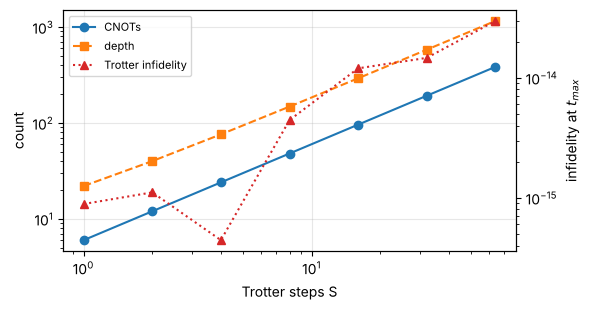

In [5]:
SECTION = "2 4x4 example (IV A)"
A, b = sq.paper_4x4(); N = 4; n = 2
x_ref = np.linalg.solve(A, b); lam = np.linalg.eigvalsh(A)
op = sq.pauli_op(A)
terms = {str(p): float(c.real) for p, c in zip(op.paulis, op.coeffs)}
print("Pauli decomposition:", terms)
check("Pauli decomposition A = 5 II + XZ + 2 YY + 3 ZX", terms, {"II": 5.0, "XZ": 1.0, "YY": 2.0, "ZX": 3.0})
nonid = [p for p in op.paulis if str(p) != "II"]
check("non-identity strings commute (Trotter exact)", all(p.commutes(q) for i, p in enumerate(nonid) for q in nonid[i+1:]), True)
check("eigenvalues", lam.round(10).tolist(), [1.0, 3.0, 5.0, 11.0])
M, dt, SHOTS, S = 8, 0.25, 2000, 4
times = dt * np.arange(1, M + 1)
check("Nyquist: dt = 0.25 <= pi/Delta lambda", np.pi / (lam[-1] - lam[0]), 0.25, cond=dt <= np.pi / (lam[-1] - lam[0]))
print(f"Gershgorin bound on the width: {sq.spectral_width_bound(A):.1f} (true width {lam[-1]-lam[0]:.1f})")

# Fig. 2: CNOT count, depth and Trotter infidelity versus S
rows = []
for s_ in (1, 2, 4, 8, 16, 32, 64):
    cx, depth = sq.circuit_cost(op, b, times[-1], s_)
    rows.append(dict(S=s_, CNOTs=cx, depth=depth, infidelity=sq.trotter_infidelity(op, A, b, times[-1], s_)))
cost4 = pd.DataFrame(rows); print(cost4.to_string(index=False, formatters={"infidelity": "{:.2e}".format}))
check("CNOTs = 6 S for S = 1..64", cost4.CNOTs.tolist(), (6 * cost4.S).tolist())
check("S=1: CNOTs, depth", (int(cost4.CNOTs[0]), int(cost4.depth[0])), (6, 22))
check("S=4: CNOTs, depth", (int(cost4.CNOTs[2]), int(cost4.depth[2])), (24, 76))
check("Trotter infidelity below 3e-14 for all S", float(cost4.infidelity.max()), 3e-14, cond=cost4.infidelity.max() < 3e-14)

fig, ax1 = plt.subplots(figsize=(6, 3.2))
ax1.loglog(cost4.S, cost4.CNOTs, "o-", label="CNOTs"); ax1.loglog(cost4.S, cost4.depth, "s--", label="depth")
ax1.set(xlabel="Trotter steps S", ylabel="count"); ax1.grid(alpha=0.3)
ax2 = ax1.twinx(); ax2.semilogy(cost4.S, np.maximum(cost4.infidelity, 1e-16), "^:", color="C3", label="Trotter infidelity")
ax2.set_ylabel("infidelity at $t_{max}$")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax1.legend(h1 + h2, l1 + l2, fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/s_analysis.pdf"); plt.show()

In [6]:
# Table I: exact time-dependent distributions p(z|t_j)
P_ex = np.array(sq.exact_probs(A, b, times))
labels = [format(i, "02b") for i in range(N)]
print(pd.DataFrame(P_ex.round(3), columns=[f"p(|{l}>)" for l in labels], index=pd.Index(times, name="t_j")))
TABLE_I = np.array([[0.137, 0.125, 0.343, 0.394], [0.069, 0.543, 0.225, 0.163], [0.212, 0.323, 0.184, 0.281],
                    [0.239, 0.125, 0.575, 0.061], [0.213, 0.401, 0.238, 0.148], [0.932, 0.043, 0.006, 0.019],
                    [0.627, 0.226, 0.052, 0.095], [0.119, 0.333, 0.442, 0.105]])
check("Table I: max |p(z|t_j) - paper|", float(np.abs(P_ex - TABLE_I).max()), 0.0, cond=np.abs(P_ex - TABLE_I).max() <= 5.01e-4)

# Table II: noiseless AerSimulator (seed 42), all M circuits in one batched job
sim = BackendRunner("simulator", seed=42)
circs = [sq.build_evolution_circuit(op, b, t, S) for t in times]
cnt_sim = sq.counts_per_time(sim.run_batch(circs, SHOTS), N)
TABLE_II = np.array([[266, 259, 699, 776], [127, 1118, 422, 333], [393, 663, 367, 577], [484, 235, 1159, 122],
                     [420, 781, 501, 298], [1860, 85, 11, 44], [1266, 440, 113, 181], [235, 689, 850, 226]])
print(pd.DataFrame(cnt_sim, columns=[f"|{l}>" for l in labels], index=pd.Index(times, name="t_j")))
check("Table II: counts per time point (seed 42)", cnt_sim.tolist(), TABLE_II.tolist())
agg = cnt_sim.sum(0); p_hat = agg / agg.sum(); p_agg = P_ex.mean(0); sig = sq.pooled_sigma(P_ex, SHOTS)
check("Table II: pooled counts", agg.tolist(), [5051, 4270, 4122, 2557])
check("Table II: empirical p_agg", p_hat.round(4).tolist(), [0.3157, 0.2669, 0.2576, 0.1598])
check("Table II: exact p_agg", p_agg.round(4).tolist(), [0.3186, 0.2650, 0.2581, 0.1583])
check("Table II: pooled standard error sigma_z", sig.round(4).tolist(), [0.0029, 0.0033, 0.0032, 0.0027])

# Galerkin solution and the capture bound of Eq. (capture)
C = sq.configuration_set(agg, b); x_sqd = sq.galerkin(A, b, C)
check("R = N = 4 configurations", len(C), 4)
check("solution x_SQD", x_sqd.round(4).tolist(), [0.1939, -0.1394, 0.2606, 0.4061])
check("F = 1 to machine precision", sq.metrics(A, x_ref, x_sqd)["F"], 1.0, atol=1e-12)
check("log of the miss probability of the least probable configuration", float(-M * SHOTS * p_agg.min()), -2500.0,
      cond=-M * SHOTS * p_agg.min() < -2500)
check("p(|00>|t=1.5) = 93.2 %", round(100 * P_ex[5, 0], 1), 93.2)
check("p(|10>|t=1.0) = 57.5 %", round(100 * P_ex[3, 2], 1), 57.5)

      p(|00>)  p(|01>)  p(|10>)  p(|11>)
t_j                                     
0.25    0.137    0.125    0.343    0.394
0.50    0.069    0.543    0.225    0.163
0.75    0.212    0.323    0.184    0.281
1.00    0.239    0.125    0.575    0.061
1.25    0.213    0.401    0.238    0.148
1.50    0.932    0.043    0.006    0.019
1.75    0.627    0.226    0.052    0.095
2.00    0.119    0.333    0.442    0.105
[PASS] Table I: max |p(z|t_j) - paper|: 0.0004955   (paper: 0)
      |00>  |01>  |10>  |11>
t_j                         
0.25   266   259   699   776
0.50   127  1118   422   333
0.75   393   663   367   577
1.00   484   235  1159   122
1.25   420   781   501   298
1.50  1860    85    11    44
1.75  1266   440   113   181
2.00   235   689   850   226
[PASS] Table II: counts per time point (seed 42): [[266, 259, 699, 776], [127, 1118, 422, 333], [393, 663, 367, 577], [484, 235, 1159, 122], [420, 781, 501, 298], [1860, 85, 11, 44], [1266, 440, 113, 181], [235, 689, 850, 226]]   (paper:

In [7]:
# Table III and Fig. 3: deviation of the sampled distributions from the exact ones
noisy = BackendRunner("noisy_simulator", noise_model=nm, seed=42)
platforms = {"Noiseless simulator": cnt_sim, "Noisy simulator": sq.counts_per_time(noisy.run_batch(circs, SHOTS), N)}
if os.path.exists(HW_FILE):
    hw = json.load(open(HW_FILE))
    platforms["ibm_fez"] = np.array(hw["counts_per_time"])
    print(f"hardware counts loaded from {HW_FILE} (job {hw.get('job_id')}, backend {hw.get('backend')})")
else:
    print(f"{HW_FILE} not found: hardware row and markers skipped (see the export cell of the self-contained notebook)")

rows = []
for name, cnt in platforms.items():
    P_hat = cnt / cnt.sum(1, keepdims=True); ph = cnt.sum(0) / cnt.sum()
    z = (ph - p_agg) / sig
    rows.append(dict(platform=name, TVD_agg=sq.tvd(ph, p_agg),
                     TVD_mean_per_time=np.mean([sq.tvd(P_hat[j], P_ex[j]) for j in range(M)]),
                     chi2=float((z**2).sum()), max_abs_z=float(np.abs(z).max()),
                     R=len(sq.configuration_set(cnt.sum(0), b)),
                     F=sq.metrics(A, x_ref, sq.galerkin(A, b, sq.configuration_set(cnt.sum(0), b)))["F"]))
tvd_tab = pd.DataFrame(rows); print(tvd_tab.round(4).to_string(index=False))
shot_agg = sq.shot_noise_tvd(sig)
shot_t = np.mean([sq.shot_noise_tvd(np.sqrt(P_ex[j] * (1 - P_ex[j]) / SHOTS)) for j in range(M)])
print(f"shot-noise reference: TVD_agg {shot_agg:.4f}, per time {shot_t:.4f}, chi2 {N-1} +/- {np.sqrt(2*(N-1)):.1f}")

PAPER_III = {"Noiseless simulator": (0.0033, 0.012, 1.6, 1.0), "Noisy simulator": (0.0251, 0.077, 135.6, 9.2),
             "ibm_fez": (0.0542, 0.119, 405.8, 13.5)}
for r in rows:
    p = PAPER_III[r["platform"]]
    check(f"Table III {r['platform']}: TVD_agg, mean TVD, chi2, max|z|",
          (round(r["TVD_agg"], 4), round(r["TVD_mean_per_time"], 4), round(r["chi2"], 1), round(r["max_abs_z"], 1)), p, atol=6e-4)
    check(f"Table III {r['platform']}: R and F", (r["R"], round(r["F"], 12)), (4, 1.0))
check("Table III shot noise: TVD_agg and per-time TVD", (round(shot_agg, 4), round(shot_t, 3)), (0.0048, 0.013))

data/ibm_fez_4x4_counts.json not found: hardware row and markers skipped (see the export cell of the self-contained notebook)
           platform  TVD_agg  TVD_mean_per_time     chi2  max_abs_z  R   F
Noiseless simulator   0.0033             0.0123   1.6130     0.9873  4 1.0
    Noisy simulator   0.0251             0.0765 135.5928     9.1650  4 1.0
shot-noise reference: TVD_agg 0.0048, per time 0.0131, chi2 3 +/- 2.4
[PASS] Table III Noiseless simulator: TVD_agg, mean TVD, chi2, max|z|: (0.0033, np.float64(0.0123), 1.6, 1.0)   (paper: (0.0033, 0.012, 1.6, 1.0))
[PASS] Table III Noiseless simulator: R and F: (4, 1.0)   (paper: (4, 1.0))
[PASS] Table III Noisy simulator: TVD_agg, mean TVD, chi2, max|z|: (0.0251, np.float64(0.0765), 135.6, 9.2)   (paper: (0.0251, 0.077, 135.6, 9.2))
[PASS] Table III Noisy simulator: R and F: (4, 1.0)   (paper: (4, 1.0))
[PASS] Table III shot noise: TVD_agg and per-time TVD: (np.float64(0.0048), np.float64(0.013))   (paper: (0.0048, 0.013))


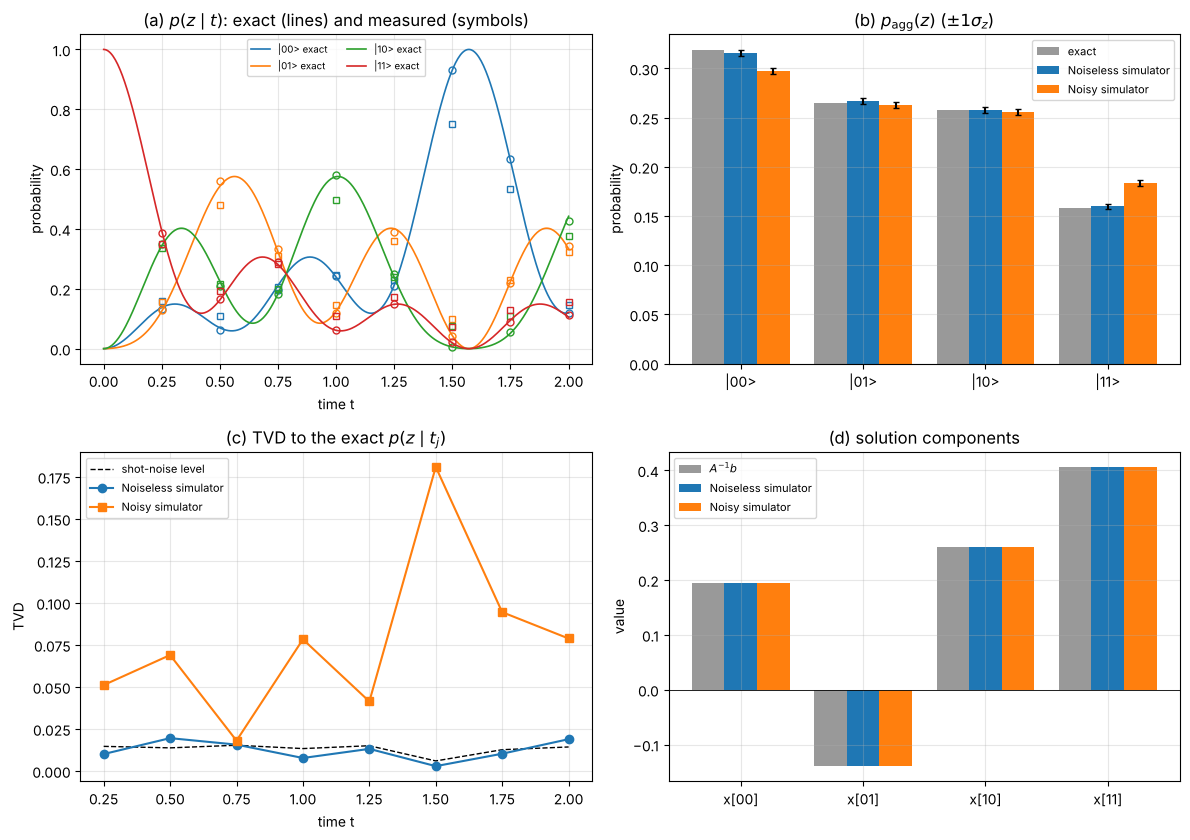

 R                C  F_SQD  F_oracle
 1             [11] 0.5689    0.5689
 2         [00, 11] 0.6957    0.8025
 3     [00, 01, 11] 0.7205    0.9124
 4 [00, 01, 10, 11] 1.0000    1.0000


In [8]:
# Fig. 3 (panels as in the paper; hardware markers only if the stored counts are present)
colors = plt.cm.tab10(np.arange(N)); mk = {"Noiseless simulator": "o", "Noisy simulator": "s", "ibm_fez": "D"}
fig, ax = plt.subplots(2, 2, figsize=(12, 8.5))
tt = np.linspace(0, times[-1], 400)
P_fine = np.vstack([np.eye(N)[np.argmax(np.abs(b))], np.array(sq.exact_probs(A, b, tt[1:]))])
for k in range(N):
    ax[0, 0].plot(tt, P_fine[:, k], color=colors[k], lw=1.2, label=f"|{labels[k]}> exact")
    for name, cnt in platforms.items():
        ax[0, 0].plot(times, cnt[:, k] / cnt.sum(1), mk[name], color=colors[k], ms=5,
                      mfc=colors[k] if name == "ibm_fez" else "none")
ax[0, 0].set(title=r"(a) $p(z\mid t)$: exact (lines) and measured (symbols)", xlabel="time t", ylabel="probability"); ax[0, 0].legend(fontsize=7, ncol=2)
w = 0.8 / (len(platforms) + 1); idx = np.arange(N)
ax[0, 1].bar(idx - 0.4 + w/2, p_agg, w, color="0.6", label="exact")
for i, (name, cnt) in enumerate(platforms.items(), start=1):
    ax[0, 1].bar(idx - 0.4 + w/2 + i*w, cnt.sum(0) / cnt.sum(), w, yerr=sig, capsize=2, label=name)
ax[0, 1].set_xticks(idx, [f"|{l}>" for l in labels]); ax[0, 1].set(title=r"(b) $p_{\rm agg}(z)$ ($\pm1\sigma_z$)", ylabel="probability"); ax[0, 1].legend(fontsize=8)
ax[1, 0].plot(times, [sq.shot_noise_tvd(np.sqrt(P_ex[j] * (1 - P_ex[j]) / SHOTS)) for j in range(M)], "k--", lw=1, label="shot-noise level")
for name, cnt in platforms.items():
    P_hat = cnt / cnt.sum(1, keepdims=True)
    ax[1, 0].plot(times, [sq.tvd(P_hat[j], P_ex[j]) for j in range(M)], mk[name] + "-", label=name)
ax[1, 0].set(title=r"(c) TVD to the exact $p(z\mid t_j)$", xlabel="time t", ylabel="TVD"); ax[1, 0].legend(fontsize=8)
ax[1, 1].bar(idx - 0.4 + w/2, x_ref, w, color="0.6", label="$A^{-1}b$")
for i, (name, cnt) in enumerate(platforms.items(), start=1):
    ax[1, 1].bar(idx - 0.4 + w/2 + i*w, sq.galerkin(A, b, sq.configuration_set(cnt.sum(0), b)), w, label=name)
ax[1, 1].axhline(0, color="k", lw=0.6); ax[1, 1].set_xticks(idx, [f"x[{l}]" for l in labels])
ax[1, 1].set(title="(d) solution components", ylabel="value"); ax[1, 1].legend(fontsize=8)
for a in ax.ravel(): a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/hardware_vs_simulation.pdf"); plt.show()

# Truncated 4x4 subspaces (frequency ranking vs oracle), discussed in Sec. IV A
rows = []
for R_ in range(1, N + 1):
    Ct = sq.configuration_set(agg, b, max_R=R_)
    rows.append(dict(R=R_, C=[labels[i] for i in Ct], F_SQD=sq.metrics(A, x_ref, sq.galerkin(A, b, Ct))["F"],
                     F_oracle=sq.metrics(A, x_ref, sq.galerkin(A, b, sq.oracle_set(x_ref, R_)))["F"]))
print(pd.DataFrame(rows).round(4).to_string(index=False))

---
## 3. Localized problem, $N=1024$ (Sec. IV B, Tables IV and V)
Screened Poisson operator $A=-\Delta_h+0.5\,\mathbb I$ with a point source at $z_0=N/2$; $\Delta t=\pi/4$ (Gershgorin), $M=8$,
2000 shots per time point. Sampling uses the exact distributions (`sq.sample_exact`, seed 0); the circuit rows of Table IV use
Lie–Trotter circuits on the noiseless simulator.

In [9]:
SECTION = "3 localized (IV B)"
NL = 1024
A_l, b_l = sq.screened_poisson_system(NL, 0.5); z0 = NL // 2
x_l = spla.spsolve(A_l.tocsc(), b_l)
ev = np.linalg.eigvalsh(A_l.toarray())
check("Gershgorin bound on the width", sq.spectral_width_bound(A_l), 4.0, atol=1e-12)
check("true spectral width at n = 10", round(ev[-1] - ev[0], 5), 3.99998)
check("participation ratio", round(1 / np.sum((x_l / np.linalg.norm(x_l))**4), 2), 2.45)
dt_l = np.pi / sq.spectral_width_bound(A_l)
times_l = lambda M_: dt_l * np.arange(1, M_ + 1)
F_l = lambda C: sq.metrics(A_l, x_l, sq.galerkin(A_l, b_l, C))["F"]

counts0 = sq.sample_exact(A_l, b_l, times_l(8), 2000, seed=0)
C0 = sq.configuration_set(counts0, b_l); m0 = sq.metrics(A_l, x_l, sq.galerkin(A_l, b_l, C0))
check("untruncated R (seed 0)", len(C0), 33)
check("window z0 +/- 16", (int(C0.min()), int(C0.max())), (z0 - 16, z0 + 16))
check("1 - F", float(1 - m0["F"]), 1.2e-10, atol=0.05e-10)
check("relative error eta", m0["rel_err"], 1.1e-5, atol=0.05e-5)

spread = {}
for M_ in (8, 32):
    Rs, es = [], []
    for s in range(30):
        C_ = sq.configuration_set(sq.sample_exact(A_l, b_l, times_l(M_), 2000, seed=s), b_l)
        Rs.append(len(C_)); es.append(sq.metrics(A_l, x_l, sq.galerkin(A_l, b_l, C_))["rel_err"])
    spread[M_] = (Rs, es)
    print(f"M={M_}: R min/median/max = {min(Rs)}/{np.median(Rs)}/{max(Rs)}, eta min/max = {min(es):.2e}/{max(es):.2e}")
check("M=8, 30 seeds: R range and median", (min(spread[8][0]), max(spread[8][0]), float(np.median(spread[8][0]))), (31, 35, 33.0))
check("M=8, 30 seeds: eta range (units of 1e-5)", (round(min(spread[8][1]) * 1e5, 1), round(max(spread[8][1]) * 1e5, 1)), (0.8, 2.2))
check("M=32, seed 0: R", len(sq.configuration_set(sq.sample_exact(A_l, b_l, times_l(32), 2000, seed=0), b_l)), 109)
check("M=32, 30 seeds: R range and median", (min(spread[32][0]), max(spread[32][0]), float(np.median(spread[32][0]))), (109, 114, 111.5))
e32 = sq.metrics(A_l, x_l, sq.galerkin(A_l, b_l, sq.configuration_set(sq.sample_exact(A_l, b_l, times_l(32), 2000, seed=0), b_l)))["rel_err"]
check("M=32, seed 0: error at machine precision", e32, 6e-17, cond=e32 < 1e-15)

[PASS] Gershgorin bound on the width: 4   (paper: 4)
[PASS] true spectral width at n = 10: 4   (paper: 4)
[PASS] participation ratio: 2.45   (paper: 2.45)
[PASS] untruncated R (seed 0): 33   (paper: 33)
[PASS] window z0 +/- 16: (496, 528)   (paper: (496, 528))
[PASS] 1 - F: 1.164e-10   (paper: 1.2e-10)
[PASS] relative error eta: 1.079e-05   (paper: 1.1e-05)


M=8: R min/median/max = 31/33.0/35, eta min/max = 7.86e-06/2.16e-05


M=32: R min/median/max = 109/111.5/114, eta min/max = 1.55e-17/5.72e-17
[PASS] M=8, 30 seeds: R range and median: (31, 35, 33.0)   (paper: (31, 35, 33.0))
[PASS] M=8, 30 seeds: eta range (units of 1e-5): (0.8, 2.2)   (paper: (0.8, 2.2))
[PASS] M=32, seed 0: R: 109   (paper: 109)
[PASS] M=32, 30 seeds: R range and median: (109, 114, 111.5)   (paper: (109, 114, 111.5))


[PASS] M=32, seed 0: error at machine precision: 5.722e-17   (paper: 6e-17)


In [10]:
# Table IV: banded family, circuits (N = 64, 128) and exact sampling (N = 64 ... 1024)
rows = []
if RUN_CIRCUITS:
    for N_ in (64, 128):
        rows.append(run_case("banded", N_, "simulator"))
for N_ in (64, 128, 256, 512, 1024):
    rows.append(run_case("banded", N_, "exact-emulation"))
tab4 = pd.DataFrame(rows)[["mode", "N", "S", "trotter_inf", "cx_per_circuit", "R", "R_over_N", "rel_err", "R_trunc", "F_trunc_SQD", "F_trunc_oracle"]]
print(tab4.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
for r in rows:
    if r["mode"] == "simulator":
        exact_C = set(run_case("banded", r["N"], "exact-emulation")["C"].tolist())
        check(f"Table IV circuits N={r['N']}: S, CNOTs, R", (int(r["S"]), int(r["cx_per_circuit"]), r["R"]),
              (64, {64: 21248, 128: 45312}[r["N"]], 32))
        check(f"Table IV circuits N={r['N']}: Trotter infidelity", round(r["trotter_inf"], 4), 0.0025)
        check(f"Table IV circuits N={r['N']}: eta", r["rel_err"], 1.7e-5, atol=0.05e-5)
        check(f"Table IV circuits N={r['N']}: configurations outside the exact window", len(set(r["C"].tolist()) - exact_C), 0)
    else:
        check(f"Table IV exact N={r['N']}: R, R/N", (r["R"], round(r["R_over_N"], 3)),
              (33, {64: 0.516, 128: 0.258, 256: 0.129, 512: 0.064, 1024: 0.032}[r["N"]]))
        check(f"Table IV exact N={r['N']}: eta", r["rel_err"], 1.1e-5, atol=0.05e-5)
    check(f"Table IV {r['mode']} N={r['N']}: F_trunc (SQD = oracle)", (round(r["F_trunc_SQD"], 3), round(r["F_trunc_oracle"], 3)),
          ({64: 0.995}.get(r["N"], 1.0),) * 2)

           mode    N   S  trotter_inf  cx_per_circuit  R  R_over_N   rel_err  R_trunc  F_trunc_SQD  F_trunc_oracle
      simulator   64  64     0.002457       2.125e+04 32       0.5 1.706e-05        8       0.9952          0.9952
      simulator  128  64     0.002457       4.531e+04 32      0.25 1.706e-05       16            1               1
exact-emulation   64 NaN            0             NaN 33    0.5156 1.079e-05        8       0.9952          0.9952
exact-emulation  128 NaN            0             NaN 33    0.2578 1.079e-05       16            1               1
exact-emulation  256 NaN            0             NaN 33    0.1289 1.079e-05       32            1               1
exact-emulation  512 NaN            0             NaN 33   0.06445 1.079e-05       64            1               1
exact-emulation 1024 NaN            0             NaN 33   0.03223 1.079e-05      128            1               1
[PASS] Table IV circuits N=64: S, CNOTs, R: (64, 21248, 32)   (paper: (64, 21248

In [11]:
# Table V: truncated subspaces, N = 1024, seed 0
rng = np.random.default_rng(1)
order = [int(i) for i in np.argsort(-counts0, kind="stable") if counts0[i] > 0]
others = np.delete(np.arange(NL), z0)
rows = []
for R in (2, 4, 8, 16, 32):
    rows.append(dict(R=R, SQD=F_l(sq.configuration_set(counts0, b_l, max_R=R)), SQD_without_supp_b=F_l(order[:R]),
                     oracle=F_l(sq.oracle_set(x_l, R)), greedy=sq.metrics(A_l, x_l, sq.greedy_residual(A_l, b_l, R, [z0])[0])["F"],
                     random_with_source=np.mean([F_l(np.r_[z0, rng.choice(others, R - 1, replace=False)]) for _ in range(1000)]),
                     random_without_source=np.mean([F_l(rng.choice(NL, R, replace=False)) for _ in range(1000)])))
tab5 = pd.DataFrame(rows); print(tab5.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
PAPER_V = {2: (0.745, 0.000, 0.745, 0.745, 0.600), 4: (0.931, 0.931, 0.931, 0.931, 0.601), 8: (0.995, 0.995, 0.995, 0.995, 0.602),
           16: (0.99998, 0.99998, 0.99998, 0.99998, 0.603)}
for r in rows:
    if r["R"] in PAPER_V:
        nd = 5 if r["R"] == 16 else 3
        check(f"Table V R={r['R']}: SQD, without supp(b), oracle, greedy, random+source",
              tuple(round(r[k], nd) for k in ("SQD", "SQD_without_supp_b", "oracle", "greedy")) + (round(r["random_with_source"], 3),),
              PAPER_V[r["R"]])
r32 = rows[-1]
check("Table V R=32: 1 - F below 1e-9 for SQD, without supp(b), oracle, greedy",
      max(1 - r32[k] for k in ("SQD", "SQD_without_supp_b", "oracle", "greedy")), 1e-9,
      cond=max(1 - r32[k] for k in ("SQD", "SQD_without_supp_b", "oracle", "greedy")) < 1e-9)
check("Table V R=32: random with source", round(r32["random_with_source"], 3), 0.611)
check("Table V: random without source <= 0.02", round(tab5.random_without_source.max(), 3), 0.02, cond=tab5.random_without_source.max() <= 0.02)

 R      SQD  SQD_without_supp_b   oracle   greedy  random_with_source  random_without_source
 2 0.744828                   0 0.744828 0.744828            0.600434                 0.0012
 4  0.93069             0.93069  0.93069  0.93069            0.600869                  0.003
 8 0.995238            0.995238 0.995238 0.995238            0.602462                 0.0036
16 0.999981            0.999981 0.999981 0.999981            0.602752             0.00674483
32        1                   1        1        1            0.611486              0.0187448
[PASS] Table V R=2: SQD, without supp(b), oracle, greedy, random+source: (0.745, 0.0, 0.745, 0.745, np.float64(0.6))   (paper: (0.745, 0.0, 0.745, 0.745, 0.6))
[PASS] Table V R=4: SQD, without supp(b), oracle, greedy, random+source: (0.931, 0.931, 0.931, 0.931, np.float64(0.601))   (paper: (0.931, 0.931, 0.931, 0.931, 0.601))
[PASS] Table V R=8: SQD, without supp(b), oracle, greedy, random+source: (0.995, 0.995, 0.995, 0.995, np.float64(0

---
## 4. Noise, shots, and Trotter errors (Sec. IV C, Fig. 4(c)–(d))
Same random-number stream as the package script `tests/t5.py` (seed 5), so the numbers are identical to the paper.

In [12]:
SECTION = "4 noise, shots, Trotter (IV C)"
rng = np.random.default_rng(5)
P_l = sq.exact_probs(A_l, b_l, times_l(8))
noise = {}
for pf in (0.0, 1e-3, 1e-2, 5e-2):
    r = []
    for rep in range(5):
        cnt = sq.sample_counts(P_l, 2000, rng, readout_flip=pf, n=10); obs = np.flatnonzero(cnt); order_ = np.argsort(-cnt)
        topS = list(dict.fromkeys([z0] + list(order_[:15])))
        r.append((len(obs), sq.metrics(A_l, x_l, sq.galerkin(A_l, b_l, obs))["Anorm"], F_l(order_[:16]), F_l(topS)))
    r = np.array(r); noise[pf] = dict(R_mean=r[:, 0].mean(), Anorm_max=r[:, 1].max(), F_top16=r[:, 2].mean(), F_top16_with_source=r[:, 3].mean())
noise_tab = pd.DataFrame(noise).T; print(noise_tab.to_string(float_format=lambda v: f"{v:.4g}"))
check("readout flips 0, 1e-3, 1e-2, 5e-2: mean R", tuple(int(round(noise[p]["R_mean"])) for p in noise), (33, 103, 214, 519))
check("energy-norm error decreases from ~2e-5 to ~2e-10", (float(f"{noise[0.0]['Anorm_max']:.0e}"), float(f"{noise[5e-2]['Anorm_max']:.0e}")), (2e-5, 2e-10))
check("truncation to R=16: F = 0.99998 at all noise levels", tuple(round(noise[p]["F_top16"], 5) for p in noise), (0.99998,) * 4)

shots_res = {}
for s in (20, 100, 500, 2000, 20000):
    rr = []
    for rep in range(5):
        obs = np.flatnonzero(sq.sample_counts(P_l, s, rng)); m = sq.metrics(A_l, x_l, sq.galerkin(A_l, b_l, obs))
        rr.append((len(obs), m["F"], m["rel_err"]))
    rr = np.array(rr); shots_res[s] = dict(R_mean=rr[:, 0].mean(), F_mean=rr[:, 1].mean(), rel_err_mean=rr[:, 2].mean())
shots_tab = pd.DataFrame(shots_res).T; print(shots_tab.to_string(float_format=lambda v: f"{v:.4g}"))
check("20 shots: R and eta", (int(round(shots_res[20]["R_mean"])), float(f"{shots_res[20]['rel_err_mean']:.0e}")), (24, 4e-4))
check("2e4 shots: R and eta", (int(round(shots_res[20000]["R_mean"])), float(f"{shots_res[20000]['rel_err_mean']:.0e}")), (35, 5e-6))

       R_mean  Anorm_max  F_top16  F_top16_with_source
0.000    32.8  2.158e-05        1                    1
0.001   103.2   8.53e-06        1                    1
0.010     214  5.268e-09        1                    1
0.050   519.4  2.328e-10        1                    1
[PASS] readout flips 0, 1e-3, 1e-2, 5e-2: mean R: (33, 103, 214, 519)   (paper: (33, 103, 214, 519))
[PASS] energy-norm error decreases from ~2e-5 to ~2e-10: (2e-05, 2e-10)   (paper: (2e-05, 2e-10))
[PASS] truncation to R=16: F = 0.99998 at all noise levels: (np.float64(0.99998), np.float64(0.99998), np.float64(0.99998), np.float64(0.99998))   (paper: (0.99998, 0.99998, 0.99998, 0.99998))
       R_mean  F_mean  rel_err_mean
20       24.4       1      0.000368
100        29       1     6.577e-05
500        31       1     2.767e-05
2000     32.8       1     1.706e-05
20000    35.4       1     4.855e-06
[PASS] 20 shots: R and eta: (24, 0.0004)   (paper: (24, 0.0004))
[PASS] 2e4 shots: R and eta: (35, 5e-06)   (paper: (

In [13]:
# Proposition 1 with circuits: hidden 8x8 blocks (N = 16, L = 136), b in one block
op_h = sq.pauli_op(A_h); lam_h = np.linalg.eigvalsh(A_h)
times_h = np.pi / (lam_h[-1] - lam_h[0]) * np.arange(1, 9)
cnt_h = sq.sample_counts(sq.exact_probs(A_h, b_h, times_h), 2000, np.random.default_rng(7))
C_h = np.flatnonzero(cnt_h)
check("hidden block: L", len(op_h), 136)
check("exact dynamics: R = N/2 inside the Krylov support, exact solution",
      (len(C_h), set(C_h) <= set(S_kr), round(sq.metrics(A_h, x_h, sq.galerkin(A_h, b_h, C_h))["F"], 12)), (8, True, 1.0))
for S_ in (2, 8):
    cnt_t = sq.sample_configurations(op_h, b_h, times_h, 2000, S_, BackendRunner("simulator", seed=3))
    C_t = np.flatnonzero(cnt_t)
    check(f"Trotter S={S_}: R, spurious configurations outside the support, F",
          (len(C_t), len(set(C_t) - set(S_kr)), round(sq.metrics(A_h, x_h, sq.galerkin(A_h, b_h, C_t))["F"], 12)), (16, 8, 1.0))

[PASS] hidden block: L: 136   (paper: 136)
[PASS] exact dynamics: R = N/2 inside the Krylov support, exact solution: (8, True, 1.0)   (paper: (8, True, 1.0))


[PASS] Trotter S=2: R, spurious configurations outside the support, F: (16, 8, 1.0)   (paper: (16, 8, 1.0))


[PASS] Trotter S=8: R, spurious configurations outside the support, F: (16, 8, 1.0)   (paper: (16, 8, 1.0))


---
## 5. Circuit cost and dense matrices (Sec. IV D, Fig. 4(b), Table VI)

In [14]:
SECTION = "5 circuit cost, dense (IV D)"
rows = []
for n_ in range(2, 11):
    Ab = sq.screened_poisson(n_, 0.5); op_ = sq.pauli_op(Ab); w_ = np.linalg.eigvalsh(Ab.toarray())
    rows.append(dict(n=n_, N=2**n_, L=len(op_), max_weight=max(sum(ch != "I" for ch in str(p)) for p in op_.paulis),
                     true_width=w_[-1] - w_[0], gershgorin=sq.spectral_width_bound(Ab), pauli_bound=sq.spectral_width_bound(Ab, method="pauli")))
t4 = pd.DataFrame(rows); print(t4.to_string(index=False, float_format=lambda v: f"{v:.5f}"))
check("tridiagonal operator: L = N for n = 2..10", t4.L.tolist(), t4.N.tolist())
check("maximum Pauli weight = n", t4.max_weight.tolist(), t4.n.tolist())
check("Pauli-sum bound = 2n", t4.pauli_bound.round(8).tolist(), (2.0 * t4.n).tolist())
check("Gershgorin bound = 4", t4.gershgorin.round(8).tolist(), [4.0] * len(t4))

cx_step = {}
for n_ in range(3, 8):
    op_ = sq.pauli_op(sq.screened_poisson(n_, 0.5).toarray())
    qc = QuantumCircuit(n_); qc.append(PauliEvolutionGate(op_, time=0.1, synthesis=LieTrotter(reps=1)), range(n_))
    cx_step[n_] = transpile(qc, basis_gates=sq.BASIS_GATES, optimization_level=1, seed_transpiler=1).count_ops().get("cx", 0)
print("CNOTs per Trotter step:", cx_step)
check("CNOTs per Trotter step, n = 3..7", list(cx_step.values()), [20, 60, 148, 332, 708])

A6, b6 = sq.screened_poisson_system(64, 0.5); op6 = sq.pauli_op(A6)
inf6 = {S_: sq.trotter_infidelity(op6, A6, b6, 2 * np.pi, S_) for S_ in (4, 16, 64)}
print("n = 6, t = 2 pi, Trotter infidelity:", {k: f"{v:.3g}" for k, v in inf6.items()})
check("n=6, t=2pi, S=64: infidelity", round(inf6[64], 4), 0.0025)
check("n=6, S=64: CNOTs per circuit (about 2e4)", sq.circuit_cost(op6, b6, 2 * np.pi, 64)[0], 21248)

 n    N    L  max_weight  true_width  gershgorin  pauli_bound
 2    4    4           2     3.23607     4.00000      4.00000
 3    8    8           3     3.75877     4.00000      6.00000
 4   16   16           4     3.93189     4.00000      8.00000
 5   32   32           5     3.98189     4.00000     10.00000
 6   64   64           6     3.99533     4.00000     12.00000
 7  128  128           7     3.99881     4.00000     14.00000
 8  256  256           8     3.99970     4.00000     16.00000
 9  512  512           9     3.99992     4.00000     18.00000
10 1024 1024          10     3.99998     4.00000     20.00000
[PASS] tridiagonal operator: L = N for n = 2..10: [4, 8, 16, 32, 64, 128, 256, 512, 1024]   (paper: [4, 8, 16, 32, 64, 128, 256, 512, 1024])
[PASS] maximum Pauli weight = n: [2, 3, 4, 5, 6, 7, 8, 9, 10]   (paper: [2, 3, 4, 5, 6, 7, 8, 9, 10])
[PASS] Pauli-sum bound = 2n: [4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 18.0, 20.0]   (paper: [4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 18.0, 

n = 6, t = 2 pi, Trotter infidelity: {4: '0.996', 16: '0.0456', 64: '0.00246'}
[PASS] n=6, t=2pi, S=64: infidelity: 0.0025   (paper: 0.0025)


[PASS] n=6, S=64: CNOTs per circuit (about 2e4): 21248   (paper: 21248)


In [15]:
# Table VI: dense random SPD matrices with dense b, truncation to R = 8 (same seeds as tests/t8.py)
def dense_instance(A, b, rng, R=8):
    x = np.linalg.solve(A, b); w = np.linalg.eigvalsh(A); dl = float(w[-1] - w[0])
    Fd = lambda C: sq.metrics(A, x, sq.galerkin(A, b, C))["F"]
    P1 = np.mean(sq.exact_probs(A, b, 0.25 * np.arange(1, 9)), axis=0)
    P2 = np.mean(sq.exact_probs(A, b, (np.pi / dl) * np.arange(1, 9)), axis=0)
    return dict(dl=dl, grid=0.25 * dl / np.pi, exact_4x4_grid=Fd(np.argsort(-P1)[:R]), exact_nyquist=Fd(np.argsort(-P2)[:R]),
                random=float(np.mean([Fd(rng.choice(len(b), R, replace=False)) for _ in range(200)])), oracle=Fd(sq.oracle_set(x, R)),
                greedy=sq.metrics(A, x, sq.greedy_residual(A, b, R, [int(np.argmax(np.abs(b)))])[0])["F"])

PAPER_VI = {16: dict(dl=66, grid=5, exact_4x4_grid=(0.46, 0.13), exact_nyquist=(0.68, 0.14), random=(0.47, 0.01), oracle=(0.88, 0.05), greedy=(0.88, 0.05)),
            32: dict(dl=262, grid=21, exact_4x4_grid=(0.23, 0.13), exact_nyquist=(0.48, 0.14), random=(0.22, 0.01), oracle=(0.61, 0.07), greedy=(0.60, 0.07)),
            64: dict(dl=1035, grid=82, exact_4x4_grid=(0.10, 0.06), exact_nyquist=(0.25, 0.08), random=(0.10, 0.01), oracle=(0.33, 0.04), greedy=(0.34, 0.03)),
            128: dict(dl=4108, grid=327, exact_4x4_grid=(0.04, 0.02), exact_nyquist=(0.13, 0.05), random=(0.05, 0.00), oracle=(0.17, 0.04), greedy=(0.18, 0.01))}
if RUN_DENSE_ENSEMBLE:
    t0 = time.time(); rows6 = []
    for N_ in (16, 32, 64, 128):
        inst = []
        for s in range(30):
            g = np.random.default_rng(1000 * N_ + s); Q = g.random((N_, N_)); A_d = Q @ Q.T + N_ * np.eye(N_); b_d = g.random(N_)
            inst.append(dense_instance(A_d, b_d, g))
        d = pd.DataFrame(inst); row = dict(N=N_, L=N_ * (N_ + 1) // 2)
        for k in d.columns:
            row[k] = (d[k].mean(), d[k].std(ddof=1))
        rows6.append(row)
        p = PAPER_VI[N_]
        check(f"Table VI N={N_}: Delta lambda and grid step", (round(row["dl"][0]), round(row["grid"][0])), (p["dl"], p["grid"]))
        for k in ("exact_4x4_grid", "exact_nyquist", "random", "oracle", "greedy"):
            check(f"Table VI N={N_}: {k} (mean, std)", (round(row[k][0], 2), round(row[k][1], 2)), p[k])
    print(pd.DataFrame([{k: (f"{v[0]:.2f} +/- {v[1]:.2f}" if isinstance(v, tuple) else v) for k, v in r.items()} for r in rows6]).to_string(index=False))
    print(f"dense ensemble: {time.time() - t0:.0f} s")
else:
    print("dense ensemble skipped (RUN_DENSE_ENSEMBLE = False)")

# Lie-Trotter with S = 4 on the dense single instances (Sec. IV D): infidelity at t = 2
for N_, paper in ((16, 0.995), (32, 0.98)):
    A_d, b_d = sq.random_spd(N_); op_d = sq.pauli_op(A_d)
    mats = [(float(c.real), sp.csr_matrix(p.to_matrix(sparse=True))) for p, c in zip(op_d.paulis, op_d.coeffs)]
    psi0 = b_d / np.linalg.norm(b_d); psi = psi0.astype(complex)
    for _ in range(4):
        for c, P in mats:
            psi = np.cos(c * 2 / 4) * psi - 1j * np.sin(c * 2 / 4) * (P @ psi)
    inf = 1 - abs(np.vdot(sl.expm(-2j * A_d) @ psi0, psi))**2
    check(f"dense N={N_}, S=4, t=2: Trotter infidelity", round(inf, 3 if N_ == 16 else 2), paper)

[PASS] Table VI N=16: Delta lambda and grid step: (66, 5)   (paper: (66, 5))
[PASS] Table VI N=16: exact_4x4_grid (mean, std): (np.float64(0.46), np.float64(0.13))   (paper: (0.46, 0.13))
[PASS] Table VI N=16: exact_nyquist (mean, std): (np.float64(0.68), np.float64(0.14))   (paper: (0.68, 0.14))
[PASS] Table VI N=16: random (mean, std): (np.float64(0.47), np.float64(0.01))   (paper: (0.47, 0.01))
[PASS] Table VI N=16: oracle (mean, std): (np.float64(0.88), np.float64(0.05))   (paper: (0.88, 0.05))
[PASS] Table VI N=16: greedy (mean, std): (np.float64(0.88), np.float64(0.05))   (paper: (0.88, 0.05))


[PASS] Table VI N=32: Delta lambda and grid step: (262, 21)   (paper: (262, 21))
[PASS] Table VI N=32: exact_4x4_grid (mean, std): (np.float64(0.23), np.float64(0.13))   (paper: (0.23, 0.13))
[PASS] Table VI N=32: exact_nyquist (mean, std): (np.float64(0.48), np.float64(0.14))   (paper: (0.48, 0.14))
[PASS] Table VI N=32: random (mean, std): (np.float64(0.22), np.float64(0.01))   (paper: (0.22, 0.01))
[PASS] Table VI N=32: oracle (mean, std): (np.float64(0.61), np.float64(0.07))   (paper: (0.61, 0.07))
[PASS] Table VI N=32: greedy (mean, std): (np.float64(0.6), np.float64(0.07))   (paper: (0.6, 0.07))


[PASS] Table VI N=64: Delta lambda and grid step: (1035, 82)   (paper: (1035, 82))
[PASS] Table VI N=64: exact_4x4_grid (mean, std): (np.float64(0.1), np.float64(0.06))   (paper: (0.1, 0.06))
[PASS] Table VI N=64: exact_nyquist (mean, std): (np.float64(0.25), np.float64(0.08))   (paper: (0.25, 0.08))
[PASS] Table VI N=64: random (mean, std): (np.float64(0.1), np.float64(0.01))   (paper: (0.1, 0.01))
[PASS] Table VI N=64: oracle (mean, std): (np.float64(0.33), np.float64(0.04))   (paper: (0.33, 0.04))
[PASS] Table VI N=64: greedy (mean, std): (np.float64(0.34), np.float64(0.03))   (paper: (0.34, 0.03))


[PASS] Table VI N=128: Delta lambda and grid step: (4108, 327)   (paper: (4108, 327))
[PASS] Table VI N=128: exact_4x4_grid (mean, std): (np.float64(0.04), np.float64(0.02))   (paper: (0.04, 0.02))
[PASS] Table VI N=128: exact_nyquist (mean, std): (np.float64(0.13), np.float64(0.05))   (paper: (0.13, 0.05))
[PASS] Table VI N=128: random (mean, std): (np.float64(0.05), np.float64(0.0))   (paper: (0.05, 0.0))
[PASS] Table VI N=128: oracle (mean, std): (np.float64(0.17), np.float64(0.04))   (paper: (0.17, 0.04))
[PASS] Table VI N=128: greedy (mean, std): (np.float64(0.18), np.float64(0.01))   (paper: (0.18, 0.01))
  N    L                dl            grid exact_4x4_grid exact_nyquist        random        oracle        greedy
 16  136    65.69 +/- 5.79   5.23 +/- 0.46  0.46 +/- 0.13 0.68 +/- 0.14 0.47 +/- 0.01 0.88 +/- 0.05 0.88 +/- 0.05
 32  528   262.48 +/- 9.26  20.89 +/- 0.74  0.23 +/- 0.13 0.48 +/- 0.14 0.22 +/- 0.01 0.61 +/- 0.07 0.60 +/- 0.07
 64 2080 1035.31 +/- 16.94  82.39 +/- 1

---
## 6. Scaling with the matrix dimension (Sec. IV E, Fig. 5)
Banded and dense families with a point source; circuits on the noiseless and noisy simulators, and exact sampling.
$S$ is the smallest power of two with Trotter infidelity below $10^{-2}$ at $t_{\max}$ (at most 64).

In [16]:
SECTION = "6 scaling (IV E)"
PLAN = [("banded", [4, 8, 16, 32, 64, 128], "simulator"), ("banded", [4, 8, 16], "noisy_simulator"),
        ("banded", [4, 8, 16, 32, 64, 128, 256, 512, 1024], "exact-emulation"),
        ("dense", [4, 8, 16, 32], "simulator"), ("dense", [4, 8], "noisy_simulator"),
        ("dense", [4, 8, 16, 32, 64, 128, 256], "exact-emulation")]
t0 = time.time(); rows = []
for fam, sizes, mode in PLAN:
    if mode != "exact-emulation" and not RUN_CIRCUITS:
        continue
    for N_ in sizes:
        rows.append(run_case(fam, N_, mode))
scal = pd.DataFrame(rows).drop(columns="C")
print(scal.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print(f"scaling test: {time.time() - t0:.0f} s")
scal.to_csv("sqd_scalability_results.csv", index=False)
get = lambda fam, mode, N_: scal[(scal.family == fam) & (scal["mode"] == mode) & (scal.N == N_)].iloc[0]
check("banded exact: R = 33 for N >= 64", [int(get("banded", "exact-emulation", N_).R) for N_ in (64, 128, 256, 512, 1024)], [33] * 5)
if RUN_CIRCUITS:
    check("banded, R = 2: noisy simulator N=8 and noiseless simulator N=16 below the oracle",
          (round(get("banded", "noisy_simulator", 8).F_trunc_SQD, 2), round(get("banded", "simulator", 16).F_trunc_SQD, 2),
           round(get("banded", "noisy_simulator", 8).F_trunc_oracle, 2), round(get("banded", "simulator", 16).F_trunc_oracle, 3)),
          (0.61, 0.60, 0.76, 0.745))
    check("dense circuits at N=32: CNOTs per circuit (~1e4)", int(get("dense", "simulator", 32).cx_per_circuit), 10496)
check("dense exact: R/N at N = 128, 256", (round(get("dense", "exact-emulation", 128).R_over_N, 2), round(get("dense", "exact-emulation", 256).R_over_N, 2)), (0.88, 0.47))
check("dense exact: untruncated error at N = 128, 256 (a few 1e-2)",
      (round(get("dense", "exact-emulation", 128).rel_err, 3), round(get("dense", "exact-emulation", 256).rel_err, 3)), (0.044, 0.082))
check("dense exact: all configurations sampled up to N = 64", int(get("dense", "exact-emulation", 64).R), 64)

family            mode    N   L   S  trotter_inf  cx_per_circuit   R  R_over_N      F   rel_err  A_norm_err  R_trunc  F_trunc_SQD  F_trunc_oracle  seconds
banded       simulator    4   4  32     0.003585             128   4         1      1         0           0        2       0.8586          0.8586      0.3
banded       simulator    8   8  64     0.003382            1280   8         1      1         0           0        2       0.7592          0.7592      1.4
banded       simulator   16  16  32      0.00953            1920  16         1      1         0           0        2       0.6001           0.745      1.9
banded       simulator   32  32  64     0.002455            9472  32         1      1         0           0        4       0.9307          0.9307       10
banded       simulator   64  64  64     0.002457       2.125e+04  32       0.5      1 1.706e-05   1.706e-05        8       0.9952          0.9952     23.5
banded       simulator  128 128  64     0.002457       4.531e+04  32  

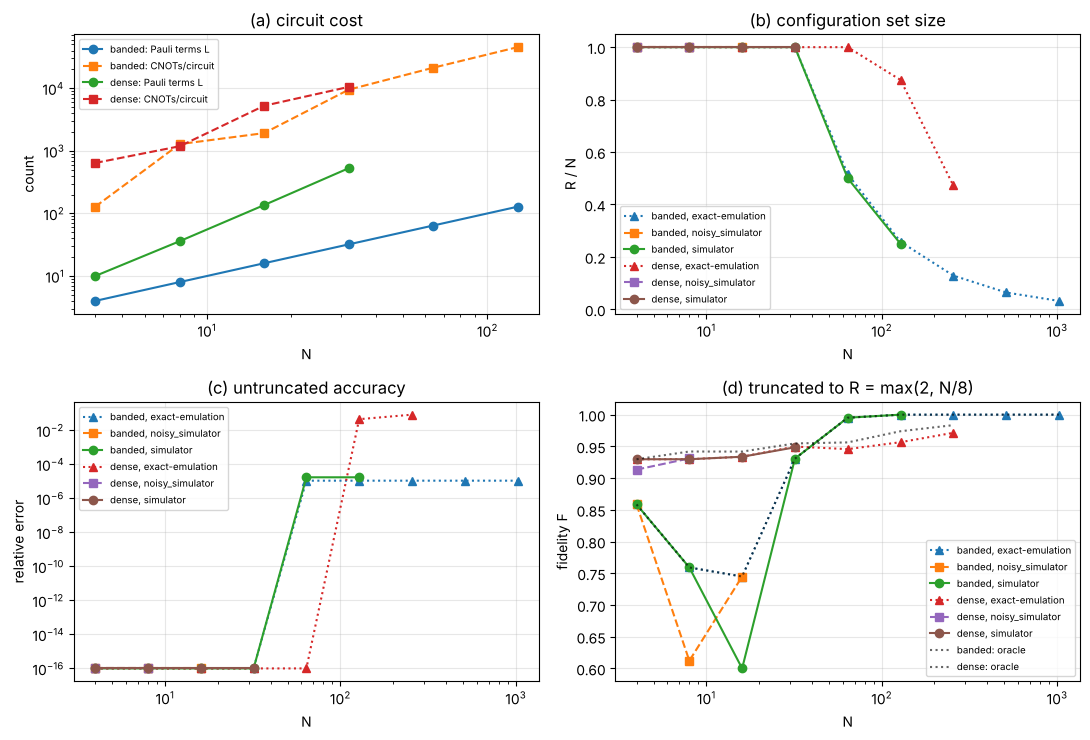

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
mk = {"simulator": "o-", "noisy_simulator": "s--", "exact-emulation": "^:"}
for (fam, mode), g in scal.groupby(["family", "mode"]):
    lab = f"{fam}, {mode}"
    if mode == "simulator":
        ax[0, 0].loglog(g.N, g.L, "o-", label=f"{fam}: Pauli terms L"); ax[0, 0].loglog(g.N, g.cx_per_circuit, "s--", label=f"{fam}: CNOTs/circuit")
    ax[0, 1].semilogx(g.N, g.R_over_N, mk[mode], label=lab)
    ax[1, 0].loglog(g.N, np.maximum(g.rel_err, 1e-16), mk[mode], label=lab)
    ax[1, 1].semilogx(g.N, g.F_trunc_SQD, mk[mode], label=lab)
for fam, g in scal[scal["mode"] == "exact-emulation"].groupby("family"):
    ax[1, 1].semilogx(g.N, g.F_trunc_oracle, "k:", alpha=0.6, label=f"{fam}: oracle")
ax[0, 0].set(title="(a) circuit cost", xlabel="N", ylabel="count"); ax[0, 1].set(title="(b) configuration set size", xlabel="N", ylabel="R / N")
ax[1, 0].set(title="(c) untruncated accuracy", xlabel="N", ylabel="relative error"); ax[1, 1].set(title="(d) truncated to R = max(2, N/8)", xlabel="N", ylabel="fidelity F")
for a in ax.ravel(): a.grid(alpha=0.3); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/scalability.pdf"); plt.show()

---
## 7. Classical comparison (Sec. IV F) and Fig. 4

[PASS] classical Krylov support with 16 mat-vecs: size: 33   (paper: 33)
[PASS] Krylov support equals the sampled set: True   (paper: True)
[PASS] same fidelity to ten digits: 1   (paper: 1)
[PASS] conjugate gradients: iterations to residual 1e-10: 34   (paper: 34)


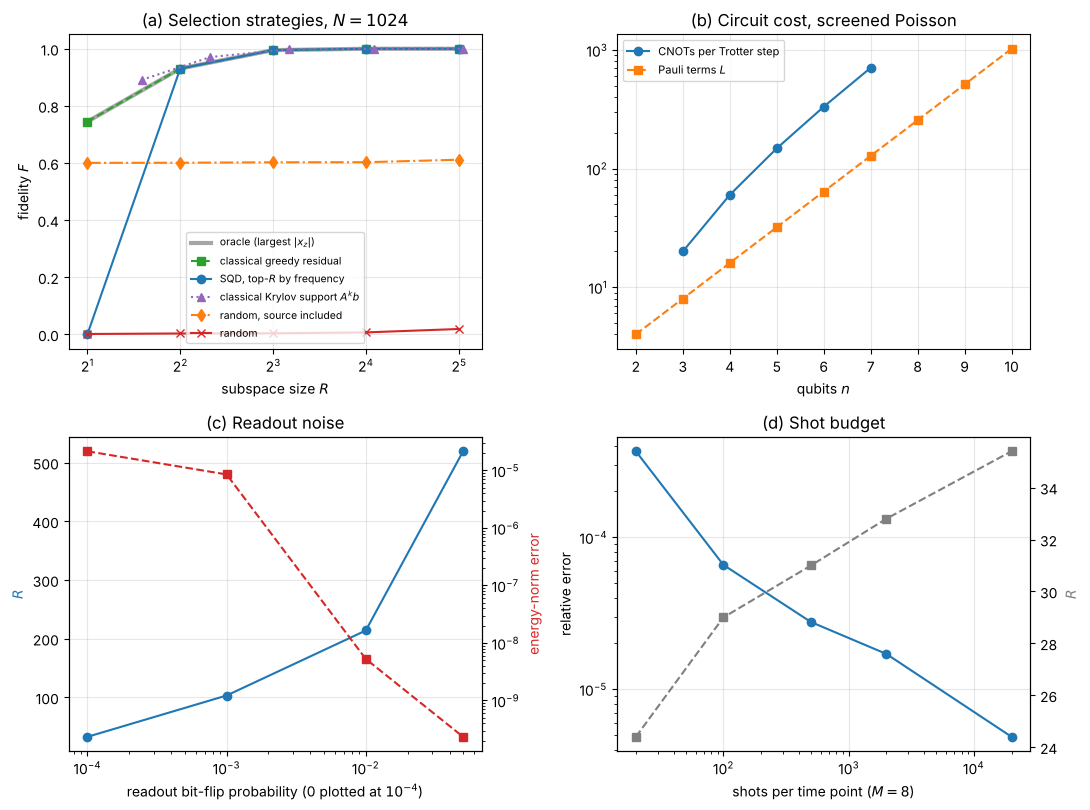

In [18]:
SECTION = "7 classical comparison (IV F)"
S16 = sq.krylov_support(A_l, b_l, 16)
check("classical Krylov support with 16 mat-vecs: size", len(S16), 33)
check("Krylov support equals the sampled set", set(S16.tolist()) == set(C0.tolist()), True)
check("same fidelity to ten digits", round(F_l(S16), 10), round(m0["F"], 10))
res = []
spla.cg(A_l, b_l, rtol=1e-10, callback=lambda xk: res.append(np.linalg.norm(A_l @ xk - b_l) / np.linalg.norm(b_l)))
check("conjugate gradients: iterations to residual 1e-10", len(res), 34)

# Fig. 4 regenerated from the data of Secs. 3-5
Rs = [2, 4, 8, 16, 32]
fig, ax = plt.subplots(2, 2, figsize=(11, 8.2))
a = ax[0, 0]
a.plot(Rs, tab5.oracle, "k-", lw=3, alpha=.35, label="oracle (largest $|x_z|$)")
a.plot(Rs, tab5.greedy, "s--", c="#2ca02c", label="classical greedy residual")
a.plot(Rs, tab5.SQD_without_supp_b, "o-", c="#1f77b4", label="SQD, top-$R$ by frequency")
kr = [(len(sq.krylov_support(A_l, b_l, k)), F_l(sq.krylov_support(A_l, b_l, k))) for k in (1, 2, 4, 8, 16)]
a.plot(*zip(*kr), "^:", c="#9467bd", label="classical Krylov support $A^kb$")
a.plot(Rs, tab5.random_with_source, "d-.", c="#ff7f0e", label="random, source included")
a.plot(Rs, tab5.random_without_source, "x-", c="#d62728", label="random")
a.set_xscale("log", base=2); a.set(xlabel="subspace size $R$", ylabel="fidelity $F$", title="(a) Selection strategies, $N=1024$"); a.legend(fontsize=7.5)
a = ax[0, 1]
a.semilogy(list(cx_step), list(cx_step.values()), "o-", label="CNOTs per Trotter step"); a.semilogy(t4.n, t4.L, "s--", label="Pauli terms $L$")
a.set(xlabel="qubits $n$", title="(b) Circuit cost, screened Poisson"); a.legend(fontsize=8)
a = ax[1, 0]; xs = [max(p, 1e-4) for p in noise]
a.semilogx(xs, noise_tab.R_mean, "o-", c="#1f77b4"); a.set_ylabel("$R$", color="#1f77b4"); a.set_xlabel("readout bit-flip probability (0 plotted at $10^{-4}$)")
a2 = a.twinx(); a2.semilogy(xs, noise_tab.Anorm_max, "s--", c="#d62728"); a2.set_ylabel("energy-norm error", color="#d62728"); a.set_title("(c) Readout noise")
a = ax[1, 1]
a.loglog(shots_tab.index, shots_tab.rel_err_mean, "o-"); a.set(xlabel="shots per time point ($M=8$)", ylabel="relative error", title="(d) Shot budget")
a3 = a.twinx(); a3.semilogx(shots_tab.index, shots_tab.R_mean, "s--", c="gray"); a3.set_ylabel("$R$", color="gray")
for a in ax.ravel(): a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/figure1.pdf"); plt.show()

---
## 8. Summary of checks

In [19]:
summary = pd.DataFrame(CHECKS)
n_ok = int(summary.ok.sum())
print(f"{n_ok} of {len(summary)} checks reproduce the paper   (total run time {time.time() - T_START:.0f} s)")
print(summary.groupby("section").ok.agg(["sum", "count"]).rename(columns={"sum": "passed", "count": "checks"}))
failed = summary[~summary.ok]
if len(failed):
    print("\nNot reproduced:"); print(failed.to_string(index=False))
summary.to_csv("reproduction_checks.csv", index=False)

144 of 144 checks reproduce the paper   (total run time 571 s)
                                passed  checks
section                                       
1 unit tests                        23      23
2 4x4 example (IV A)                25      25
3 localized (IV B)                  44      44
4 noise, shots, Trotter (IV C)       9       9
5 circuit cost, dense (IV D)        33      33
6 scaling (IV E)                     6       6
7 classical comparison (IV F)        4       4
